# Self-Attention: The Core of Modern NLP

Self-attention is the central mechanism inside every Transformer model (BERT, GPT, T5, etc.). It allows every token in a sequence to **dynamically look at all other tokens** and decide how much to "pay attention" to each one when building its own representation.

## Overview
This notebook covers self-attention mechanics from intuition to PyTorch:
1. **Motivation**: Why earlier sequence representations (BoW, Word2Vec, RNNs) fall short.
2. **Query–Key–Value Intuition**: Database lookup analogy for attention.
3. **Mathematical Formulation**: Scaled dot-product attention formula and matrix shapes.
4. **Step-by-Step NumPy Implementation**: Linear projections, score calculation, softmax, and context vectors.
5. **Pronoun Disambiguation**: Visualizing attention on coreference resolution.
6. **Multi-Head Attention**: PyTorch implementation capturing diverse relationship types.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

---
## 1. Why Self-Attention?

### The Problem With Earlier Approaches

#### 1. Bag of Words / TF-IDF
Treats each word **independently**. The sentence  
> *"The cat sat on the mat"*  

is just a set of word counts. Word order and context are completely lost.

#### 2. Static Word2Vec / GloVe Embeddings
A single, fixed vector per word.  
**"bank"** has *one* vector — whether you mean a river bank, a money bank, or a plane banking. The model cannot disambiguate.

#### 3. RNNs / LSTMs
Process tokens **left-to-right** (or right-to-left) sequentially.  
- Hard to capture long-range dependencies — information about token 1 must survive through tokens 2, 3, 4, … to reach token 20.  
- **Not parallelisable** — you must finish step t before starting step t+1.  
- Gradient signals vanish or explode over long sequences.

### The Solution: Self-Attention

Self-attention lets **every token directly attend to every other token** in a single step.  
Distance doesn't matter — token 1 and token 20 are equally reachable.  
It's **fully parallelisable** — all token pairs are processed simultaneously.

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# Polysemy demo — one word, completely different meanings depending on context
# ─────────────────────────────────────────────────────────────────────────────

examples = [
    ("I went to the river  bank  to fish.",          "bank", "riverbank / shore"),
    ("I deposited money at the  bank  yesterday.",   "bank", "financial institution"),
    ("The plane had to  bank  left to avoid storms.", "bank", "tilt / turn"),
    ("He is a real Python  snake  charmer.",          "snake", "reptile"),
    ("I traced the cable's  snake  through the wall.","snake", "threading a wire"),
]

print("POLYSEMY: the same word has different meanings based on context")
print("─" * 65)
for sentence, word, meaning in examples:
    print(f"  Sentence : {sentence}")
    print(f"  '{word}'  → means: {meaning}")
    print()

POLYSEMY: the same word has different meanings based on context
─────────────────────────────────────────────────────────────────
  Sentence : I went to the river  bank  to fish.
  'bank'  → means: riverbank / shore

  Sentence : I deposited money at the  bank  yesterday.
  'bank'  → means: financial institution

  Sentence : The plane had to  bank  left to avoid storms.
  'bank'  → means: tilt / turn

  Sentence : He is a real Python  snake  charmer.
  'snake'  → means: reptile

  Sentence : I traced the cable's  snake  through the wall.
  'snake'  → means: threading a wire



---
## 2. Query–Key–Value Framework

Self-attention borrows an analogy from **information retrieval** (think: a database or search engine).

### The Database Analogy

Imagine a small key-value store:

```
Keys (what's in the DB)    Values (the content)
────────────────────────   ──────────────────────────────────────────
"cat"                   →  fluffy, mammal, meows
"sat"                   →  past tense of sit, physical action
"mat"                   →  flat object on the floor
```

When you run a **Query** (e.g., "show me something related to seating"), the system computes how well your query matches each key.  
High match → pull more of that value into the result.

### In Self-Attention

- Every token in the sentence generates its own **Query**, **Key**, and **Value** vector.
- Queries and Keys interact through a dot product to produce **compatibility scores**.
- Scores are normalised with softmax into **attention weights** (a probability distribution).
- The output for each token is a **weighted sum of all Value vectors**.

```
Token "cat"
  Query: "who/what is near me, or acting on me?"
  Key  : "I am a noun; I am the subject; I have properties: feline, animate"
  Value: <embedding information to contribute if I am selected>
```

This happens for **all tokens, simultaneously**, in a single matrix operation.

---
## 3. Mathematical Formulation

The complete self-attention formula is:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

Breaking it down:

| Symbol | Meaning |
|--------|---------|
| $X \in \mathbb{R}^{n \times d_{model}}$ | $n$ tokens, each a $d_{model}$-dimensional vector |
| $W^Q, W^K \in \mathbb{R}^{d_{model} \times d_k}$ | Learned projection matrices for Query and Key |
| $W^V \in \mathbb{R}^{d_{model} \times d_v}$ | Learned projection matrix for Value |
| $Q = XW^Q$ | Query matrix — what each token is *asking* |
| $K = XW^K$ | Key matrix — what each token is *offering* |
| $V = XW^V$ | Value matrix — what each token *contributes* when selected |
| $QK^T / \sqrt{d_k}$ | Scaled similarity scores — an $n \times n$ matrix |
| $\text{softmax}(\cdots)$ | Normalise scores into a probability distribution |
| $\text{softmax}(\cdots) \cdot V$ | Weighted mixture of Values — the output |

### Shapes at a glance

```
X           : (n, d_model)
W_Q, W_K    : (d_model, d_k)
W_V         : (d_model, d_v)
Q, K        : (n, d_k)
V           : (n, d_v)
Q @ K.T     : (n, n)       ← attention scores matrix
softmax(…)  : (n, n)       ← attention weights matrix
Output      : (n, d_v)     ← enriched token representations
```

---
## 4. Step-by-Step NumPy Implementation

We'll work through all 5 steps using NumPy with a simple sentence — every matrix printed so you can see exactly what is happening.

### Step 1 — Input Embeddings
Each token is first mapped to a dense vector.  
In practice this comes from a learned **Embedding layer**; here we use random vectors to focus on the mechanics.

### Step 2 — Compute Q, K, V by Linear Projection

Three separate learned weight matrices transform the embeddings into **Queries, Keys, and Values**:

| Projection | Weight matrix | Output |
|------------|--------------|--------|
| Query      | $W^Q \in \mathbb{R}^{d_{model} \times d_k}$ | $Q = X W^Q$ |
| Key        | $W^K \in \mathbb{R}^{d_{model} \times d_k}$ | $K = X W^K$ |
| Value      | $W^V \in \mathbb{R}^{d_{model} \times d_v}$ | $V = X W^V$ |

> `d_k` and `d_v` can be smaller than `d_model` — this is actually desirable as it acts as a bottleneck that forces the model to learn compact representations.

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# STEPS 1 & 2 — Input Embeddings → Q, K, V Projections
# ─────────────────────────────────────────────────────────────────────────────

sentence_demo = "The cat sat on the mat".split()
seq_len_demo  = len(sentence_demo)
d_model_demo  = 6     # tiny model so matrices are printable

np.random.seed(1)
X_demo = np.random.randn(seq_len_demo, d_model_demo)   # embedding matrix

# Learnable weight matrices (randomly initialised; learned via backprop in real models)
d_k_demo_wt = 4    # key/query dimension
d_v_demo_wt = 4    # value dimension
W_Q_demo = np.random.randn(d_model_demo, d_k_demo_wt) * 0.5
W_K_demo = np.random.randn(d_model_demo, d_k_demo_wt) * 0.5
W_V_demo = np.random.randn(d_model_demo, d_v_demo_wt) * 0.5

# PROJECT
Q_manual = X_demo @ W_Q_demo   # (6, 4)
K_manual = X_demo @ W_K_demo   # (6, 4)
V_manual = X_demo @ W_V_demo   # (6, 4)

print("─" * 60)
print("Input Embeddings  X  (shape:", X_demo.shape, ")")
print(np.round(X_demo, 2))
print()
print("W_Q  (shape:", W_Q_demo.shape, ")  →  Q  (shape:", Q_manual.shape, ")")
print(np.round(Q_manual, 2))
print()
print("W_K  (shape:", W_K_demo.shape, ")  →  K  (shape:", K_manual.shape, ")")
print(np.round(K_manual, 2))
print()
print("W_V  (shape:", W_V_demo.shape, ")  →  V  (shape:", V_manual.shape, ")")
print(np.round(V_manual, 2))
print()
print("Each token now has a Query, a Key, and a Value.")

────────────────────────────────────────────────────────────
Input Embeddings  X  (shape: (6, 6) )
[[ 1.62 -0.61 -0.53 -1.07  0.87 -2.3 ]
 [ 1.74 -0.76  0.32 -0.25  1.46 -2.06]
 [-0.32 -0.38  1.13 -1.1  -0.17 -0.88]
 [ 0.04  0.58 -1.1   1.14  0.9   0.5 ]
 [ 0.9  -0.68 -0.12 -0.94 -0.27  0.53]
 [-0.69 -0.4  -0.69 -0.85 -0.67 -0.01]]

W_Q  (shape: (6, 4) )  →  Q  (shape: (6, 4) )
[[-2.39 -0.92  0.95 -1.05]
 [-2.61 -0.85  1.28 -0.1 ]
 [-0.09 -0.95 -0.29  0.5 ]
 [-0.34  0.53 -0.14 -0.36]
 [-0.12  0.45  0.95 -0.05]
 [ 0.73  0.16 -0.55 -1.37]]

W_K  (shape: (6, 4) )  →  K  (shape: (6, 4) )
[[-1.3   1.53  0.17  0.37]
 [-0.51  1.6  -0.28 -0.53]
 [ 1.3  -1.44 -1.39  0.34]
 [-1.18  1.6   1.47  0.  ]
 [-0.73  0.1  -0.2   0.33]
 [-0.55 -0.59 -0.12  0.57]]

W_V  (shape: (6, 4) )  →  V  (shape: (6, 4) )
[[ 1.47  0.23 -1.37  1.21]
 [ 0.91  0.29 -1.36  1.6 ]
 [ 0.44 -0.8   0.1  -0.07]
 [-0.43  1.3   0.12  0.45]
 [ 0.   -0.43 -0.31 -0.56]
 [ 0.34 -0.48 -0.03 -0.68]]

Each token now has a Query, a Key, 

### Step 3 — Compute Attention Scores and Scale

For each Query, compute a **raw score** against every Key using the dot product:

$$\text{score}(Q_i, K_j) = Q_i \cdot K_j$$

High score = Query and Key point in the same direction = highly relevant pair.

**Why do we scale?**  
In high dimensions ($d_k$ large), dot products grow in magnitude ~ $\sqrt{d_k}$.  
Without scaling, softmax receives huge values → its output becomes near one-hot → gradients nearly vanish.
We fix this by dividing by $\sqrt{d_k}$:

$$\text{score}_{ij} = \frac{Q_i \cdot K_j}{\sqrt{d_k}}$$

Step 3a — Raw attention scores  Q · Kᵀ  (shape: (6, 6) )
[[ 1.467  0.032 -3.446  2.722  1.127  1.146]
 [ 2.272 -0.332 -3.985  3.59   1.543  1.726]
 [-1.193 -1.657  1.82  -1.827  0.191  0.923]
 [ 1.095  1.249 -1.136  1.041  0.213 -0.31 ]
 [ 0.991  0.551 -2.161  2.267 -0.069 -0.34 ]
 [-1.301  0.769  1.025 -1.414 -0.866 -1.217]]

Step 3b — Scaled scores  (divided by √4 = 2.00)
[[ 0.734  0.016 -1.723  1.361  0.563  0.573]
 [ 1.136 -0.166 -1.993  1.795  0.772  0.863]
 [-0.597 -0.828  0.91  -0.913  0.096  0.462]
 [ 0.547  0.625 -0.568  0.521  0.107 -0.155]
 [ 0.496  0.276 -1.08   1.133 -0.035 -0.17 ]
 [-0.651  0.384  0.513 -0.707 -0.433 -0.608]]


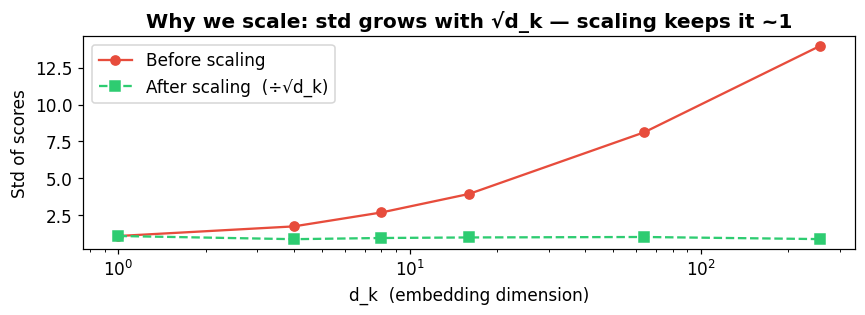

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — Attention Scores and Scaling
# ─────────────────────────────────────────────────────────────────────────────

# 3a. Raw scores: how much does each Query match each Key?
raw_scores_manual = Q_manual @ K_manual.T          # (6, 6)
print("Step 3a — Raw attention scores  Q · Kᵀ  (shape:", raw_scores_manual.shape, ")")
print(np.round(raw_scores_manual, 3))

# 3b. Scale by √d_k to prevent very large dot-products in high dimensions
#     Without scaling, softmax saturates → gradients vanish during training
d_k_demo = K_manual.shape[-1]
scaled_scores_manual = raw_scores_manual / np.sqrt(d_k_demo)  # (6, 6)

print(f"\nStep 3b — Scaled scores  (divided by √{d_k_demo} = {np.sqrt(d_k_demo):.2f})")
print(np.round(scaled_scores_manual, 3))

# ── Why scaling matters — visualise the variance collapse ─────────────────
dims  = [1, 4, 8, 16, 64, 256]
stds_before = []
stds_after  = []
for d in dims:
    q = np.random.randn(10, d)
    k = np.random.randn(10, d)
    s = q @ k.T
    stds_before.append(s.std())
    stds_after.append((s / np.sqrt(d)).std())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(dims, stds_before, 'o-', label='Before scaling', color='#e74c3c')
ax.plot(dims, stds_after,  's--', label='After scaling  (÷√d_k)', color='#2ecc71')
ax.set_xlabel('d_k  (embedding dimension)'); ax.set_ylabel('Std of scores')
ax.set_title('Why we scale: std grows with √d_k — scaling keeps it ~1',
             fontweight='bold')
ax.legend(); ax.set_xscale('log')
plt.tight_layout(); plt.show()

### Step 4 — Softmax: Scores → Attention Weights

Raw scores are real numbers; we need them to form a proper **probability distribution over tokens** so we can blend the Value vectors meaningfully.

$$\text{Attention}_{ij} = \frac{\exp(\text{score}_{ij})}{\sum_{k=1}^{n} \exp(\text{score}_{ik})}$$

**Properties guaranteed by Softmax:**
- All weights are **positive** (0 to 1)
- Each row **sums to 1** — it's a valid probability distribution
- Large scores get amplified; small scores get suppressed → **sparse focus**

> **Practical note:** Softmax is applied **row-wise** — each query token has its own probability distribution over all key tokens.

Step 4 — Attention weights after Softmax  (shape: (6, 6) )
Each row sums to 1.0 — it's a probability distribution over tokens.

Attention weight matrix:
[[0.195 0.095 0.017 0.364 0.164 0.166]
 [0.213 0.058 0.009 0.411 0.148 0.162]
 [0.084 0.067 0.379 0.061 0.168 0.242]
 [0.221 0.239 0.073 0.215 0.142 0.11 ]
 [0.2   0.16  0.041 0.378 0.118 0.103]
 [0.098 0.275 0.312 0.092 0.121 0.102]]


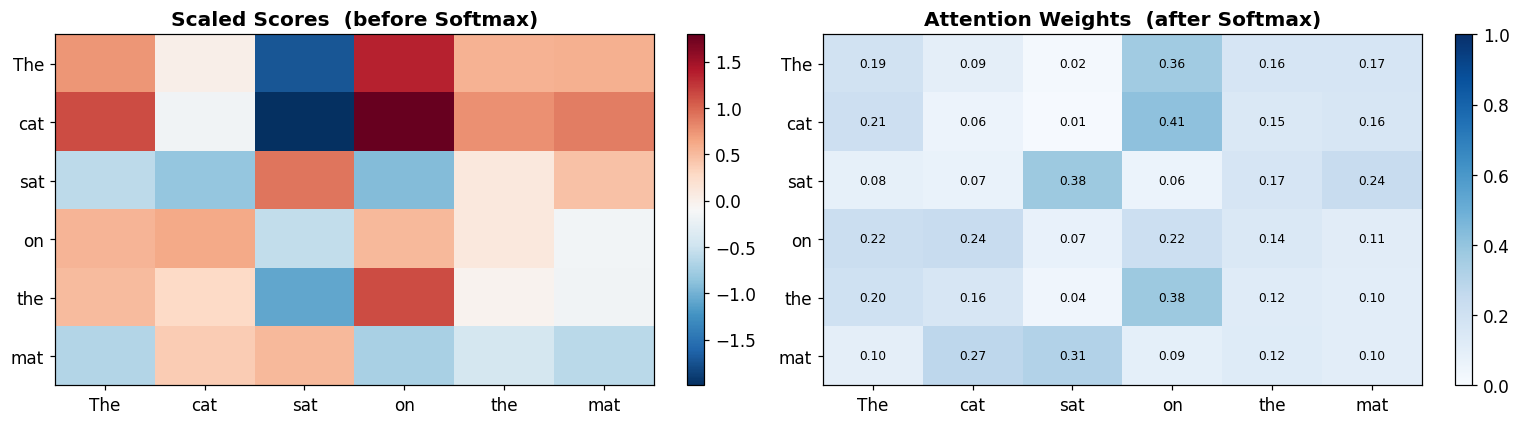

Row sums = [1. 1. 1. 1. 1. 1.]


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — Softmax: turn scores into a probability distribution
# ─────────────────────────────────────────────────────────────────────────────

def softmax(x):
    """Numerically stable row-wise softmax."""
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

attention_weights_manual = softmax(scaled_scores_manual)   # (6, 6)

print("Step 4 — Attention weights after Softmax  (shape:", attention_weights_manual.shape, ")")
print("Each row sums to 1.0 — it's a probability distribution over tokens.\n")
print("Attention weight matrix:")
print(np.round(attention_weights_manual, 3))

# ── Visualise ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
im = ax.imshow(scaled_scores_manual, cmap='RdBu_r', aspect='auto')
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(len(sentence_demo))); ax.set_xticklabels(sentence_demo)
ax.set_yticks(range(len(sentence_demo))); ax.set_yticklabels(sentence_demo)
ax.set_title('Scaled Scores  (before Softmax)', fontweight='bold')

ax = axes[1]
im2 = ax.imshow(attention_weights_manual, cmap='Blues', aspect='auto', vmin=0, vmax=1)
plt.colorbar(im2, ax=ax, fraction=0.046)
ax.set_xticks(range(len(sentence_demo))); ax.set_xticklabels(sentence_demo)
ax.set_yticks(range(len(sentence_demo))); ax.set_yticklabels(sentence_demo)
ax.set_title('Attention Weights  (after Softmax)', fontweight='bold')
for i in range(len(sentence_demo)):
    for j in range(len(sentence_demo)):
        ax.text(j, i, f'{attention_weights_manual[i,j]:.2f}',
                ha='center', va='center', fontsize=8,
                color='white' if attention_weights_manual[i,j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

print("Row sums =", np.round(attention_weights_manual.sum(axis=1), 4))

### Step 5 — Compute the Context Vector

Now multiply the attention weights by the Values.  
Each output token is a **weighted mixture** of all Value vectors:

$$\text{Output}_i = \sum_{j=1}^{n} \text{Attention}_{ij} \cdot V_j$$

Or in matrix form for the whole sequence at once:

$$\text{Context} = \underbrace{\text{Attention}}_{\scriptscriptstyle n \times n} \cdot \underbrace{V}_{\scriptscriptstyle n \times d_v} = \underbrace{\text{Context}}_{\scriptscriptstyle n \times d_v}$$

**Intuition:** The output for token `i` is a blend of all value vectors, where the blend is determined by how relevant each token was (per the attention weights).  
A word that attended *heavily* to another word's value will strongly incorporate that word's information into its own representation.

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# STEP 5 — Weighted Sum → Context Vector
# ─────────────────────────────────────────────────────────────────────────────
context_manual = attention_weights_manual @ V_manual   # (6, d_v)

print("Step 5 — Context vectors  (shape:", context_manual.shape, ")")
print("Each row is the new representation of a token, enriched by context.\n")
for word, c_vec in zip(sentence_demo, context_manual):
    print(f"  {word:6s}  {np.round(c_vec[:4], 3)} ...")   # show first 4 dims

print()
print("━" * 60)
print("Compare: original vs. context-enriched representation of 'sat'")
print(f"  Original  : {np.round(X_demo[2, :4], 3)} ...")
print(f"  Enriched  : {np.round(context_manual[2, :4], 3)} ...")
print()
print("The enriched vector for 'sat' is now a blend of all tokens,")
print("weighted by how relevant each was — 'sat' has absorbed context from")
print("'cat' and 'mat' (words it's most semantically connected to).")

Step 5 — Context vectors  (shape: (6, 4) )
Each row is the new representation of a token, enriched by context.

  The     [ 0.281  0.383 -0.407  0.344] ...
  cat     [ 0.249  0.453 -0.371  0.34 ] ...
  sat     [ 0.407 -0.373 -0.22  -0.049] ...
  on      [ 0.521  0.228 -0.643  0.587] ...
  the     [ 0.332  0.452 -0.484  0.529] ...
  mat     [ 0.527 -0.13  -0.507  0.44 ] ...

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Compare: original vs. context-enriched representation of 'sat'
  Original  : [-0.322 -0.384  1.134 -1.1  ] ...
  Enriched  : [ 0.407 -0.373 -0.22  -0.049] ...

The enriched vector for 'sat' is now a blend of all tokens,
weighted by how relevant each was — 'sat' has absorbed context from
'cat' and 'mat' (words it's most semantically connected to).


In [7]:
def self_attention_numpy(X, W_Q, W_K, W_V, verbose=False):
    """
    Scaled Dot-Product Self-Attention in pure NumPy.

    Parameters
    ----------
    X    : (seq_len, d_model) — input embeddings
    W_Q  : (d_model, d_k)    — query projection
    W_K  : (d_model, d_k)    — key projection
    W_V  : (d_model, d_v)    — value projection

    Returns
    -------
    context : (seq_len, d_v)      enriched token representations
    weights : (seq_len, seq_len)  attention distribution (rows sum to 1)
    """
    def _softmax(x):
        e = np.exp(x - x.max(axis=-1, keepdims=True))   # numerically stable
        return e / e.sum(axis=-1, keepdims=True)

    Q      = X  @ W_Q                          # (seq_len, d_k)
    K      = X  @ W_K                          # (seq_len, d_k)
    V      = X  @ W_V                          # (seq_len, d_v)
    d_k    = K.shape[-1]

    scores  = Q @ K.T / np.sqrt(d_k)           # (seq_len, seq_len) — scaled scores
    weights = _softmax(scores)                  # (seq_len, seq_len) — attention weights
    context = weights @ V                       # (seq_len, d_v)     — output

    if verbose:
        print(f"  Q : {Q.shape}   K : {K.shape}   V : {V.shape}")
        print(f"  scores  (Q@Kᵀ/√d_k) : {scores.shape}")
        print(f"  weights (softmax)    : {weights.shape}")
        print(f"  context (weights@V)  : {context.shape}")

    return context, weights


print("self_attention_numpy defined")

self_attention_numpy defined


Sentence       : ['The', 'cat', 'sat', 'on', 'the', 'mat']
X  shape       : (6, 8)  — one 8-d vector per token
  Q : (6, 8)   K : (6, 8)   V : (6, 8)
  scores  (Q@Kᵀ/√d_k) : (6, 6)
  weights (softmax)    : (6, 6)
  context (weights@V)  : (6, 8)

Context shape  : (6, 8)  — one enriched vector per token

Attention weights (row = query, col = key):
[[0.149 0.177 0.165 0.156 0.187 0.165]
 [0.19  0.152 0.169 0.175 0.15  0.165]
 [0.176 0.162 0.165 0.172 0.157 0.168]
 [0.172 0.169 0.171 0.176 0.148 0.164]
 [0.215 0.138 0.168 0.172 0.14  0.167]
 [0.18  0.162 0.167 0.176 0.151 0.165]]

Row sums (must be 1): [1. 1. 1. 1. 1. 1.]


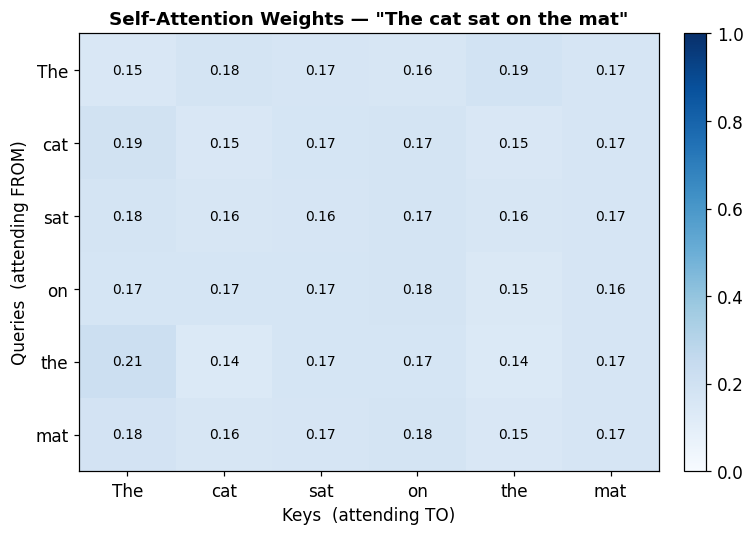

In [8]:
def plot_attention_heatmap(attn_weights, tokens, title='Attention Weights'):
    """Plot a clean attention heatmap with value annotations."""
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(attn_weights, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    n = len(tokens)
    ax.set_xticks(range(n));  ax.set_xticklabels(tokens, fontsize=11)
    ax.set_yticks(range(n));  ax.set_yticklabels(tokens, fontsize=11)
    ax.set_xlabel('Keys  (attending TO)',      fontsize=11)
    ax.set_ylabel('Queries  (attending FROM)', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{attn_weights[i, j]:.2f}',
                    ha='center', va='center', fontsize=9,
                    color='white' if attn_weights[i, j] > 0.5 else 'black')
    plt.tight_layout()
    plt.show()


# ── Set up sentence and embeddings ──────────────────────────────────────────
sentence = "The cat sat on the mat".split()
seq_len  = len(sentence)
d_model  = 8           # small, so everything is printable

np.random.seed(42)
X = np.random.randn(seq_len, d_model)   # (6, 8)  — fake pre-trained embeddings

# Weight matrices (learned in real models via back-prop; random here)
d_k = 8;  d_v = 8
W_Q = np.random.randn(d_model, d_k) * 0.1
W_K = np.random.randn(d_model, d_k) * 0.1
W_V = np.random.randn(d_model, d_v) * 0.1

print("Sentence       :", sentence)
print(f"X  shape       : {X.shape}  — one {d_model}-d vector per token")

# ── Run self-attention ───────────────────────────────────────────────────────
context, attn_weights = self_attention_numpy(X, W_Q, W_K, W_V, verbose=True)

print(f"\nContext shape  : {context.shape}  — one enriched vector per token")
print(f"\nAttention weights (row = query, col = key):")
print(np.round(attn_weights, 3))
print(f"\nRow sums (must be 1): {np.round(attn_weights.sum(axis=1), 4)}")

# ── Visualise ────────────────────────────────────────────────────────────────
plot_attention_heatmap(attn_weights, sentence,
                       title='Self-Attention Weights — "The cat sat on the mat"')

---
## 5. Pronoun Coreference Example

Consider the famous **Winograd Schema** sentence:

> *"The trophy didn't fit in the suitcase because **it** was too big."*

What does **"it"** refer to?  A human immediately knows: **the trophy** (it's the one that's too big).  
An RNN processing left-to-right would have mostly "forgotten" `trophy` by the time it reaches `it`.  
Self-attention can directly connect `it` back to `trophy` in a **single operation**.

We'll use hand-crafted 3D embeddings that encode `[size, object-ness, verb-ness]` so we can see the mechanism clearly.

> **Note:** Real models learn all of this from data — the W_Q / W_K / W_V matrices are learned to make these connections automatically.

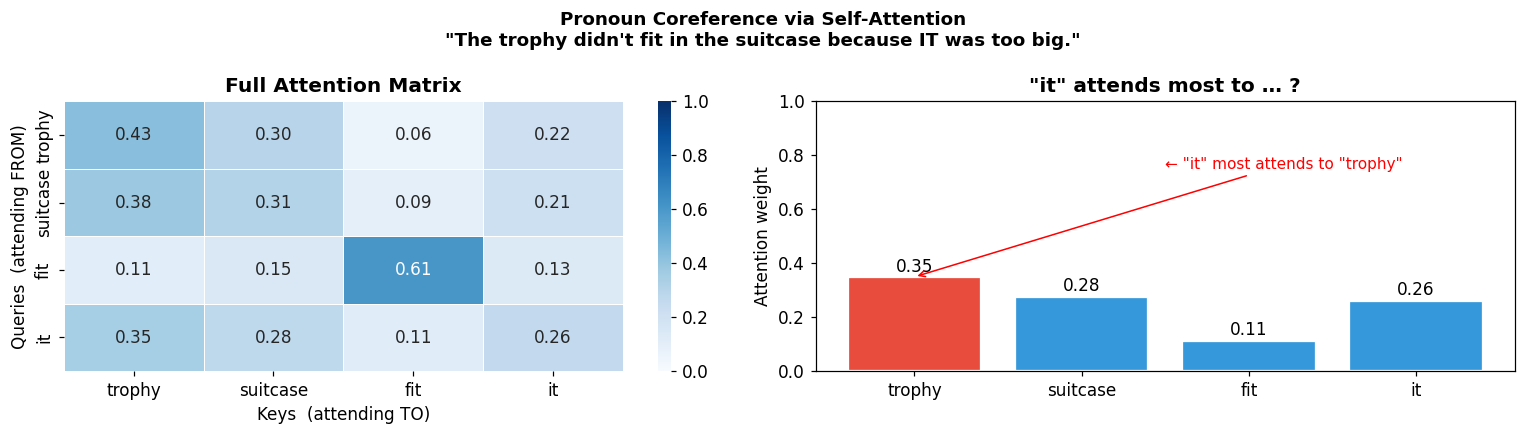


"it" attends most strongly to: "trophy"
→ Self-attention naturally aligns the pronoun with the most size-related noun.


In [9]:
# ─────────────────────────────────────────────────────────────────────────────
# A classic NLP ambiguity problem: pronoun coreference resolution
#
# "The trophy didn't fit in the suitcase because it was too big."
#
# What does "it" refer to?  → The trophy (which was too big to fit).
# A language model MUST understand context to resolve this.
# ─────────────────────────────────────────────────────────────────────────────

sentence_cr = "trophy suitcase fit it".split()   # simplified 4-token version

# Hand-craft embeddings that capture a meaningful property:
# Dim 0 = "size concept":  trophy=big(1), suitcase=medium(0.5), fit=-1, it=?
# Dim 1 = "object-ness":   trophy=1, suitcase=1, fit=0, it=0.3
# Dim 2 = "verb-ness":     trophy=0, suitcase=0, fit=1, it=0

EMB = np.array([
    #  size  obj  verb
    [  1.0,  1.0,  0.0 ],   # trophy
    [  0.5,  1.0,  0.0 ],   # suitcase
    [ -1.0,  0.0,  1.0 ],   # fit
    [  0.7,  0.3,  0.0 ],   # it  ← ambiguous pronoun
], dtype=float)

d = EMB.shape[1]

# Small W_Q, W_K, W_V (3×3); learnable in practice — fixed here for illustration
np.random.seed(0)
W_Q = np.eye(d) + 0.05 * np.random.randn(d, d)
W_K = np.eye(d) + 0.05 * np.random.randn(d, d)
W_V = np.eye(d) + 0.05 * np.random.randn(d, d)

ctx, attn = self_attention_numpy(EMB, W_Q, W_K, W_V)

# ── Visualise attention weights for "it" (row index 3) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: full attention matrix
sns.heatmap(attn, ax=axes[0],
            xticklabels=sentence_cr, yticklabels=sentence_cr,
            cmap='Blues', linewidths=0.6, linecolor='white',
            annot=True, fmt='.2f', vmin=0, vmax=1)
axes[0].set_title('Full Attention Matrix', fontweight='bold')
axes[0].set_xlabel('Keys  (attending TO)')
axes[0].set_ylabel('Queries  (attending FROM)')

# Right: bar chart for "it" row only
it_attention = attn[3]
colors = ['#e74c3c' if i == np.argmax(it_attention) else '#3498db'
          for i in range(len(sentence_cr))]
axes[1].bar(sentence_cr, it_attention, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('"it" attends most to … ?', fontweight='bold')
axes[1].set_ylabel('Attention weight')
axes[1].set_ylim(0, 1)
for i, v in enumerate(it_attention):
    axes[1].text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=11)

# Annotation
peak = sentence_cr[np.argmax(it_attention)]
axes[1].annotate(f'← "it" most attends to "{peak}"',
                 xy=(np.argmax(it_attention), max(it_attention)),
                 xytext=(1.5, 0.75),
                 arrowprops=dict(arrowstyle='->', color='red'),
                 fontsize=10, color='red')

plt.suptitle('Pronoun Coreference via Self-Attention\n'
             '"The trophy didn\'t fit in the suitcase because IT was too big."',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'\n"it" attends most strongly to: "{peak}"')
print("→ Self-attention naturally aligns the pronoun with the most size-related noun.")

---
## 6. Multi-Head Attention

A single self-attention pass asks one question of the data.  
**Multi-Head Attention** runs `h` independent attention heads in parallel, each with its own learnable W_Q, W_K, W_V matrices. The outputs are concatenated and projected back to the model dimension.

```
X  ─┬─ head₁ (W_Q¹, W_K¹, W_V¹) ─────────┐
    ├─ head₂ (W_Q², W_K², W_V²) ──────────┤  Concat  →  W_O  →  Output
    ├─ head₃ (W_Q³, W_K³, W_V³) ──────────┤
    └─ head₄ (W_Q⁴, W_K⁴, W_V⁴) ──────────┘
```

### Why does this help?

| Head (example) | What it might learn |
|----------------|---------------------|
| Head 1 | Syntactic subject–verb agreement |
| Head 2 | Coreference (pronouns → nouns) |
| Head 3 | Positional proximity |
| Head 4 | Semantic similarity |

BERT-base uses **12 heads** with d_model = 768, so each head has d_k = d_v = 64.

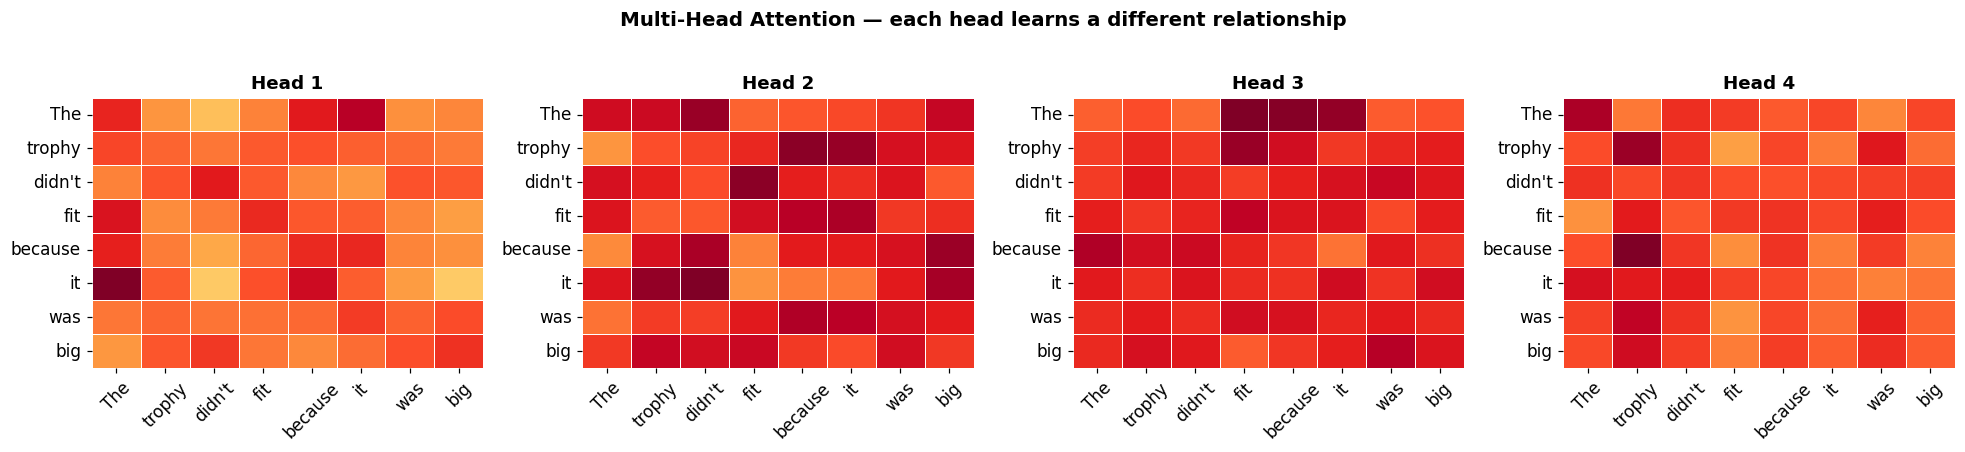


Observe how different heads focus on different token pairs —
one head might track sentence structure while another tracks co-reference.


In [10]:
def multi_head_attention(X, num_heads=4, d_model=16, d_k=None, d_v=None):
    """
    Multi-head self-attention.
    X : (seq_len, d_model)
    Returns context : (seq_len, d_model), all_weights : (num_heads, seq_len, seq_len)
    """
    if d_k is None:
        d_k = d_model // num_heads
    if d_v is None:
        d_v = d_model // num_heads

    all_heads    = []
    all_weights  = []

    for h in range(num_heads):
        W_Q = np.random.randn(d_model, d_k) * 0.1
        W_K = np.random.randn(d_model, d_k) * 0.1
        W_V = np.random.randn(d_model, d_v) * 0.1

        Q = X @ W_Q          # (seq_len, d_k)
        K = X @ W_K
        V = X @ W_V

        scores  = Q @ K.T / np.sqrt(d_k)
        weights = softmax(scores)             # (seq_len, seq_len)
        head    = weights @ V                 # (seq_len, d_v)

        all_heads.append(head)
        all_weights.append(weights)

    # Concatenate heads → (seq_len, num_heads * d_v)
    concat    = np.concatenate(all_heads, axis=-1)
    W_O       = np.random.randn(num_heads * d_v, d_model) * 0.1
    output    = concat @ W_O                  # (seq_len, d_model)
    return output, np.array(all_weights)


# ── Run it ──────────────────────────────────────────────────────────────────
sentence_mha = ["The", "trophy", "didn't", "fit", "because", "it", "was", "big"]
X_mha        = np.random.randn(len(sentence_mha), 16)   # fake embeddings
np.random.seed(7)
output_mha, mha_weights = multi_head_attention(X_mha, num_heads=4, d_model=16)

# ── Visualise each head ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for h, ax in enumerate(axes):
    sns.heatmap(mha_weights[h], ax=ax,
                xticklabels=sentence_mha, yticklabels=sentence_mha,
                cmap='YlOrRd', linewidths=0.4, linecolor='white',
                vmin=0, vmax=mha_weights[h].max(), annot=False, cbar=False)
    ax.set_title(f'Head {h+1}', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Multi-Head Attention — each head learns a different relationship',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nObserve how different heads focus on different token pairs —")
print("one head might track sentence structure while another tracks co-reference.")

---
## 7. Summary & Key Takeaways

Self-attention is conceptually elegant: every word asks **"which other words are most relevant to understanding me?"** and gathers information from them proportionally.

| Component | Role |
|-----------|------|
| **Query (Q)** | What this token is asking for |
| **Key (K)** | What each token advertises it can offer |
| **Value (V)** | The actual content contributed when selected |
| **Scores** | Dot product Q·Kᵀ measures query-key match |
| **Scale** | Divide by √d_k to stabilise gradients |
| **Softmax** | Turn scores into a probability distribution |
| **Context** | Weighted sum of Values — the enriched representation |

### Multi-Head
A single head can only look for one type of relationship at a time. Multiple heads let the model simultaneously capture **syntactic**, **semantic**, and **coreference** patterns in the same layer.